In [3]:
from google.colab import drive
drive.mount('/content/drive')

import zipfile, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

SEED = 42
np.random.seed(SEED)

BASE = Path('/content/drive/MyDrive/Klasifikasi-Diabetes')
ZIP_PATH = BASE / 'dataset.zip'
REPORT = BASE / 'reports'
REPORT.mkdir(exist_ok=True)

FILE = 'diabetes_012_health_indicators_BRFSS2015.csv'
TARGET = 'Diabetes_012'

Mounted at /content/drive


In [4]:
with zipfile.ZipFile(ZIP_PATH) as z:
      print(z.namelist())
      with z.open(FILE) as f:
          df = pd.read_csv(f)

print(df.shape)
df.head()

['diabetes_012_health_indicators_BRFSS2015.csv', 'diabetes_binary_5050split_health_indicators_BRFSS2015.csv', 'diabetes_binary_health_indicators_BRFSS2015.csv']
(253680, 22)


,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


In [5]:
BINARY = ['HighBP','HighChol','CholCheck','Smoker','Stroke','HeartDiseaseorAttack',
            'PhysActivity','Fruits','Veggies','HvyAlcoholConsump','AnyHealthcare',
            'NoDocbcCost','DiffWalk','Sex']
NUMERIC = ['BMI','MentHlth','PhysHlth']
ORDINAL = ['GenHlth','Age','Education','Income']
FEATURES = BINARY + NUMERIC + ORDINAL

assert len(FEATURES) == 21
assert set(FEATURES) == set(df.columns) - {TARGET}

In [6]:
df.info()
print('Memori (MB):', round(df.memory_usage(deep=True).sum()/1e6, 1))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Diabetes_012          253680 non-null  float64
 1   HighBP                253680 non-null  float64
 2   HighChol              253680 non-null  float64
 3   CholCheck             253680 non-null  float64
 4   BMI                   253680 non-null  float64
 5   Smoker                253680 non-null  float64
 6   Stroke                253680 non-null  float64
 7   HeartDiseaseorAttack  253680 non-null  float64
 8   PhysActivity          253680 non-null  float64
 9   Fruits                253680 non-null  float64
 10  Veggies               253680 non-null  float64
 11  HvyAlcoholConsump     253680 non-null  float64
 12  AnyHealthcare         253680 non-null  float64
 13  NoDocbcCost           253680 non-null  float64
 14  GenHlth               253680 non-null  float64
 15  

In [7]:
n = len(df)
missing = df.isna().sum().sum()
dup_full = df.duplicated().sum()

# baris fitur identik tetapi label berbeda, dihitung setelah duplikat penuh dibuang
d = df.drop_duplicates()
conflict_rows = d.duplicated(subset=FEATURES, keep=False).sum()

quality = pd.DataFrame({
    'Pemeriksaan': ['Jumlah baris', 'Missing value', 'Duplikat penuh',
                    'Baris dengan fitur identik tapi label berbeda'],
    'Hasil': [n, missing, dup_full, conflict_rows]
})
quality['Persen'] = (quality['Hasil'] / n * 100).round(2)
quality.loc[0, 'Persen'] = np.nan
quality.to_csv(REPORT/'01_kualitas_data.csv', index=False)
quality

,Pemeriksaan,Hasil,Persen
0,Jumlah baris,253680,NaN
1,Missing value,0,0.00
2,Duplikat penuh,23899,9.42
3,Baris dengan fitur identik tapi label berbeda,3707,1.46


In [8]:
EXPECTED = {'BMI':(12,98), 'MentHlth':(0,30), 'PhysHlth':(0,30),
            'GenHlth':(1,5), 'Age':(1,13), 'Education':(1,6), 'Income':(1,8)}

rows = []
for c in BINARY:
    rows.append([c, 'Biner', sorted(df[c].unique().tolist()), df[c].nunique()])
for c in NUMERIC + ORDINAL:
    rows.append([c, 'Numerik' if c in NUMERIC else 'Ordinal',
                  (df[c].min(), df[c].max()), df[c].nunique()])
rng = pd.DataFrame(rows, columns=['Atribut','Tipe','Nilai/Rentang','Nilai unik'])

# peringatan bila ada nilai di luar yang diharapkan
for c in BINARY:
    assert set(df[c].unique()) <= {0.0, 1.0}, c
for c,(lo,hi) in EXPECTED.items():
    assert df[c].min() >= lo and df[c].max() <= hi, c

rng.to_csv(REPORT/'02_rentang_nilai.csv', index=False)
rng

,Atribut,Tipe,Nilai/Rentang,Nilai unik
0,HighBP,Biner,"[0.0, 1.0]",2
1,HighChol,Biner,"[0.0, 1.0]",2
2,CholCheck,Biner,"[0.0, 1.0]",2
3,Smoker,Biner,"[0.0, 1.0]",2
4,Stroke,Biner,"[0.0, 1.0]",2
5,HeartDiseaseorAttack,Biner,"[0.0, 1.0]",2
6,PhysActivity,Biner,"[0.0, 1.0]",2
7,Fruits,Biner,"[0.0, 1.0]",2
8,Veggies,Biner,"[0.0, 1.0]",2
9,HvyAlcoholConsump,Biner,"[0.0, 1.0]",2


In [9]:
desc = df[NUMERIC + ORDINAL].describe().T
desc['skew'] = df[NUMERIC + ORDINAL].skew()
desc.round(2).to_csv(REPORT/'03_statistik_deskriptif.csv')
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,skew
BMI,253680.0,28.38,6.61,12.0,24.0,27.0,31.0,98.0,2.12
MentHlth,253680.0,3.18,7.41,0.0,0.0,0.0,2.0,30.0,2.72
PhysHlth,253680.0,4.24,8.72,0.0,0.0,0.0,3.0,30.0,2.21
GenHlth,253680.0,2.51,1.07,1.0,2.0,2.0,3.0,5.0,0.42
Age,253680.0,8.03,3.05,1.0,6.0,8.0,10.0,13.0,-0.36
Education,253680.0,5.05,0.99,1.0,4.0,5.0,6.0,6.0,-0.78
Income,253680.0,6.05,2.07,1.0,5.0,7.0,8.0,8.0,-0.89


   Nilai Target        Kategori  Jumlah  Persen
0             0  Tidak diabetes  213703   84.24
1             1     Prediabetes    4631    1.83
2             2        Diabetes   35346   13.93
Rasio kelas mayoritas : minoritas = 46.1 : 1


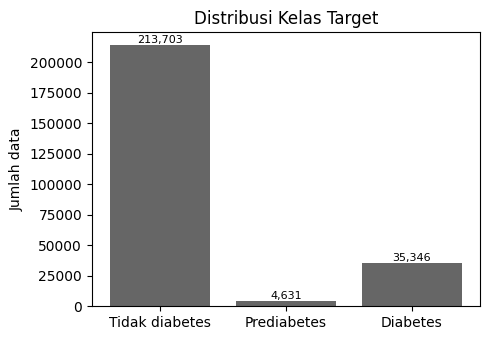

In [10]:
labels = {0:'Tidak diabetes', 1:'Prediabetes', 2:'Diabetes'}
vc = df[TARGET].astype(int).value_counts().sort_index()
dist = pd.DataFrame({
    'Nilai Target': vc.index,
    'Kategori': [labels[i] for i in vc.index],
    'Jumlah': vc.values,
    'Persen': (vc.values / n * 100).round(2)
})
dist.to_csv(REPORT/'04_distribusi_kelas.csv', index=False)
print(dist)
print('Rasio kelas mayoritas : minoritas = %.1f : 1' % (vc.max()/vc.min()))

fig, ax = plt.subplots(figsize=(5,3.5))
ax.bar(dist['Kategori'], dist['Jumlah'], color='0.4')
for i, v in enumerate(dist['Jumlah']):
    ax.text(i, v, f'{v:,}', ha='center', va='bottom', fontsize=8)
ax.set_ylabel('Jumlah data'); ax.set_title('Distribusi Kelas Target')
plt.tight_layout()
plt.savefig(REPORT/'fig_distribusi_kelas.png', dpi=300)
plt.show()

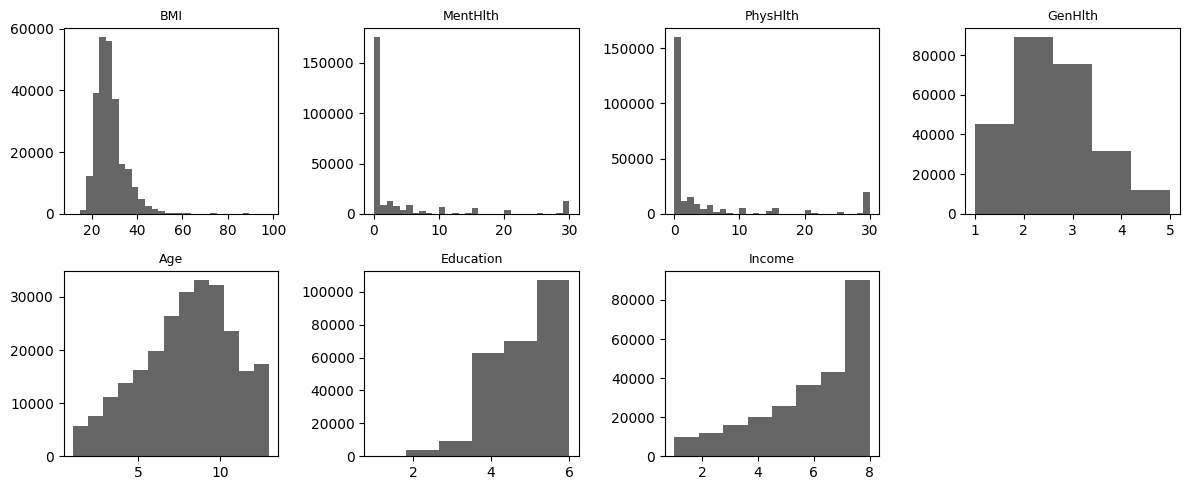

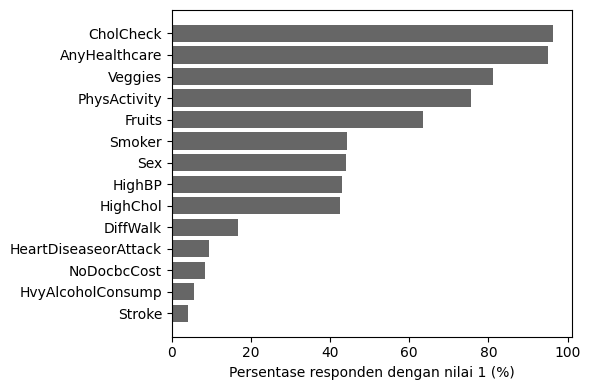

In [11]:
# fitur numerik dan ordinal: histogram
cols = NUMERIC + ORDINAL
fig, axes = plt.subplots(2, 4, figsize=(12,5))
for ax, c in zip(axes.ravel(), cols):
    ax.hist(df[c], bins=min(30, df[c].nunique()), color='0.4')
    ax.set_title(c, fontsize=9)
axes.ravel()[-1].axis('off')
plt.tight_layout()
plt.savefig(REPORT/'fig_distribusi_numerik_ordinal.png', dpi=300)
plt.show()

# fitur biner: proporsi nilai 1
prop = df[BINARY].mean().sort_values()
fig, ax = plt.subplots(figsize=(6,4))
ax.barh(prop.index, prop.values*100, color='0.4')
ax.set_xlabel('Persentase responden dengan nilai 1 (%)')
plt.tight_layout()
plt.savefig(REPORT/'fig_proporsi_biner.png', dpi=300)
plt.show()

In [12]:
meta = pd.DataFrame({'Atribut': FEATURES})
meta['Tipe'] = ['Biner']*len(BINARY) + ['Numerik']*len(NUMERIC) + ['Ordinal']*len(ORDINAL)
meta['Min'] = [df[c].min() for c in FEATURES]
meta['Max'] = [df[c].max() for c in FEATURES]
meta['Nilai unik'] = [df[c].nunique() for c in FEATURES]
meta.to_csv(REPORT/'05_deskripsi_atribut.csv', index=False)
meta

,Atribut,Tipe,Min,Max,Nilai unik
0,HighBP,Biner,0.0,1.0,2
1,HighChol,Biner,0.0,1.0,2
2,CholCheck,Biner,0.0,1.0,2
3,Smoker,Biner,0.0,1.0,2
4,Stroke,Biner,0.0,1.0,2
5,HeartDiseaseorAttack,Biner,0.0,1.0,2
6,PhysActivity,Biner,0.0,1.0,2
7,Fruits,Biner,0.0,1.0,2
8,Veggies,Biner,0.0,1.0,2
9,HvyAlcoholConsump,Biner,0.0,1.0,2


In [13]:
# distribusi kelas: asli vs setelah buang duplikat vs baris label bertentangan
mask = d.duplicated(subset=FEATURES, keep=False)
cmp = pd.DataFrame({
    'Asli': df[TARGET].astype(int).value_counts().sort_index(),
    'Setelah dedup': d[TARGET].astype(int).value_counts().sort_index(),
    'Baris bertentangan': d[mask][TARGET].astype(int).value_counts().sort_index(),
}).fillna(0).astype(int)
cmp['% bertentangan dari kelas'] = (cmp['Baris bertentangan']/cmp['Setelah dedup']*100).round(2)
cmp.to_csv(REPORT/'06_perbandingan_dedup.csv')
print(cmp, '\n')

# lonjakan di 0 dan 30 pada fitur hari sakit
for c in ['MentHlth','PhysHlth']:
    print(c, '| persen nilai 0 =', round((df[c]==0).mean()*100,1),
          '| persen nilai 30 =', round((df[c]==30).mean()*100,1))

                Asli  Setelah dedup  Baris bertentangan  \
Diabetes_012                                              
0             213703         190055                1804   
1               4631           4629                 337   
2              35346          35097                1566   

              % bertentangan dari kelas  
Diabetes_012                             
0                                  0.95  
1                                  7.28  
2                                  4.46   

MentHlth | persen nilai 0 = 69.3 | persen nilai 30 = 4.8
PhysHlth | persen nilai 0 = 63.1 | persen nilai 30 = 7.6


In [14]:
df_clean = d.reset_index(drop=True)   # d = df.drop_duplicates() dari Sel 5
assert len(df) - len(df_clean) == dup_full
assert df_clean.isna().sum().sum() == 0

ringkas = pd.DataFrame({
    'Kategori': [labels[i] for i in [0, 1, 2]],
    'Sebelum': df[TARGET].astype(int).value_counts().sort_index().values,
    'Sesudah': df_clean[TARGET].astype(int).value_counts().sort_index().values,
})
ringkas['Dihapus'] = ringkas['Sebelum'] - ringkas['Sesudah']
ringkas['% sebelum'] = (ringkas['Sebelum'] / ringkas['Sebelum'].sum() * 100).round(2)
ringkas['% sesudah'] = (ringkas['Sesudah'] / ringkas['Sesudah'].sum() * 100).round(2)
ringkas.loc[len(ringkas)] = ['Total', ringkas['Sebelum'].sum(), ringkas['Sesudah'].sum(),
                              ringkas['Dihapus'].sum(), 100.0, 100.0]
ringkas.to_csv(REPORT / '07_ringkasan_dedup.csv', index=False)
print(ringkas)

INTERIM = BASE / 'data' / 'interim'
INTERIM.mkdir(parents=True, exist_ok=True)
df_clean.to_csv(INTERIM / 'diabetes_012_dedup.csv', index=False)
print('\nDisimpan:', INTERIM / 'diabetes_012_dedup.csv', df_clean.shape)

         Kategori  Sebelum  Sesudah  Dihapus  % sebelum  % sesudah
0  Tidak diabetes   213703   190055    23648      84.24      82.71
1     Prediabetes     4631     4629        2       1.83       2.01
2        Diabetes    35346    35097      249      13.93      15.27
3           Total   253680   229781    23899     100.00     100.00

Disimpan: /content/drive/MyDrive/Klasifikasi-Diabetes/data/interim/diabetes_012_dedup.csv (229781, 22)


In [15]:
from sklearn.model_selection import train_test_split

X = df_clean[FEATURES]
y = df_clean[TARGET].astype(int)

X_train, X_tmp, y_train, y_tmp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(
    X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)

# tabel ukuran dan proporsi kelas per subset
rows = []
for nama, yy in [('Train', y_train), ('Validasi', y_val), ('Test', y_test), ('Total', y)]:
    vc = yy.value_counts().sort_index()
    rows.append([nama, len(yy)] + vc.tolist() + (vc / len(yy) * 100).round(2).tolist())
split_tbl = pd.DataFrame(rows, columns=['Subset','Jumlah','n Kelas 0','n Kelas 1','n Kelas 2',
                                        '% Kelas 0','% Kelas 1','% Kelas 2'])
split_tbl.to_csv(REPORT / '08_ringkasan_split.csv', index=False)
print(split_tbl.to_string(index=False))

# pemeriksaan
assert len(X_train) + len(X_val) + len(X_test) == len(df_clean)
assert not (set(X_train.index) & set(X_val.index))
assert not (set(X_train.index) & set(X_test.index))
assert not (set(X_val.index) & set(X_test.index))

# baris dengan fitur identik lintas subset (hanya mungkin berasal dari label bertentangan)
h = lambda A: set(pd.util.hash_pandas_object(A, index=False))
print('\nFitur test yang juga ada di train :', len(h(X_test) & h(X_train)))
print('Fitur val  yang juga ada di train :', len(h(X_val) & h(X_train)))

  Subset  Jumlah  n Kelas 0  n Kelas 1  n Kelas 2  % Kelas 0  % Kelas 1  % Kelas 2
   Train  160846     133038       3240      24568      82.71       2.01      15.27
Validasi   34467      28508        695       5264      82.71       2.02      15.27
    Test   34468      28509        694       5265      82.71       2.01      15.28
   Total  229781     190055       4629      35097      82.71       2.01      15.27

Fitur test yang juga ada di train : 389
Fitur val  yang juga ada di train : 392


In [16]:
import joblib
from sklearn.preprocessing import StandardScaler

SCALE_COLS = NUMERIC + ORDINAL     # 7 kolom; 14 kolom biner dibiarkan 0/1

scaler = StandardScaler()
scaler.fit(X_train[SCALE_COLS])

def transform(X):
    Xs = X.copy()
    Xs[SCALE_COLS] = scaler.transform(X[SCALE_COLS])
    return Xs

X_train_s, X_val_s, X_test_s = transform(X_train), transform(X_val), transform(X_test)

# pemeriksaan
chk = pd.DataFrame({
    'mean train': X_train_s[SCALE_COLS].mean().round(4),
    'std train':  X_train_s[SCALE_COLS].std().round(4),
    'mean val':   X_val_s[SCALE_COLS].mean().round(4),
    'mean test':  X_test_s[SCALE_COLS].mean().round(4),
})
print(chk)
assert X_train_s.isna().sum().sum() == 0
assert X_val_s.isna().sum().sum() == 0
assert X_test_s.isna().sum().sum() == 0
assert (X_train_s[BINARY] == X_train[BINARY]).all().all()   # biner tidak berubah
chk.to_csv(REPORT / '09_pemeriksaan_scaling.csv')

           mean train  std train  mean val  mean test
BMI              -0.0        1.0   -0.0089     0.0051
MentHlth         -0.0        1.0   -0.0028     0.0056
PhysHlth          0.0        1.0   -0.0037    -0.0080
GenHlth           0.0        1.0   -0.0012    -0.0009
Age               0.0        1.0   -0.0007    -0.0038
Education        -0.0        1.0    0.0100     0.0079
Income           -0.0        1.0    0.0044     0.0064


In [17]:
import json
from sklearn.utils.class_weight import compute_class_weight

classes = np.array([0, 1, 2])
w = compute_class_weight('balanced', classes=classes, y=y_train)
class_weights = {int(c): round(float(x), 4) for c, x in zip(classes, w)}
print('Class weight:', class_weights)

PROC = BASE / 'data' / 'processed'
PROC.mkdir(parents=True, exist_ok=True)

for nama, Xs, yy in [('train', X_train_s, y_train),
                      ('val',   X_val_s,   y_val),
                      ('test',  X_test_s,  y_test)]:
    out = Xs.copy()
    out[TARGET] = yy.values
    out.to_csv(PROC / f'{nama}.csv', index=False)
    print(nama, out.shape)

joblib.dump(scaler, PROC / 'scaler.joblib')
with open(PROC / 'class_weights.json', 'w') as f:
    json.dump(class_weights, f, indent=2)

pd.DataFrame({'Kolom di-scale': SCALE_COLS,
              'Mean train': scaler.mean_.round(4),
              'Std train': scaler.scale_.round(4)}).to_csv(PROC / 'scaler_params.csv', index=False)
print('\nIsi folder:', sorted(p.name for p in PROC.iterdir()))

Class weight: {0: 0.403, 1: 16.5479, 2: 2.1823}
train (160846, 22)
val (34467, 22)
test (34468, 22)

Isi folder: ['class_weights.json', 'scaler.joblib', 'scaler_params.csv', 'test.csv', 'train.csv', 'val.csv']
